In [2]:

# ==========================================
# 1. 필요한 라이브러리 불러오기
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 그래프 한글 설정
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 2. NOAA 실제 태풍 데이터 주소
# ==========================================

url = (
    "https://www.ncei.noaa.gov/data/"
    "international-best-track-archive-for-climate-stewardship-ibtracs/"
    "v04r01/access/csv/ibtracs.WP.list.v04r01.csv"
)

# ==========================================
# 3. 데이터 불러오기
# ==========================================

df = pd.read_csv(
    url,
    skiprows=[1],
    low_memory=False
)

# ==========================================
# 4. 데이터 확인
# ==========================================

print("태풍 데이터 불러오기 성공!")
print("--------------------------------")
print("데이터 행과 열:", df.shape)

print("\n데이터 열 이름:")
print(df.columns.tolist())

print("\n데이터 앞부분:")
display(df.head())

print("\n데이터 정보:")
df.info()


태풍 데이터 불러오기 성공!
--------------------------------
데이터 행과 열: (249256, 174)

데이터 열 이름:
['SID', 'SEASON', 'NUMBER', 'BASIN', 'SUBBASIN', 'NAME', 'ISO_TIME', 'NATURE', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'WMO_AGENCY', 'TRACK_TYPE', 'DIST2LAND', 'LANDFALL', 'IFLAG', 'USA_AGENCY', 'USA_ATCF_ID', 'USA_LAT', 'USA_LON', 'USA_RECORD', 'USA_STATUS', 'USA_WIND', 'USA_PRES', 'USA_SSHS', 'USA_R34_NE', 'USA_R34_SE', 'USA_R34_SW', 'USA_R34_NW', 'USA_R50_NE', 'USA_R50_SE', 'USA_R50_SW', 'USA_R50_NW', 'USA_R64_NE', 'USA_R64_SE', 'USA_R64_SW', 'USA_R64_NW', 'USA_POCI', 'USA_ROCI', 'USA_RMW', 'USA_EYE', 'TOKYO_LAT', 'TOKYO_LON', 'TOKYO_GRADE', 'TOKYO_WIND', 'TOKYO_PRES', 'TOKYO_R50_DIR', 'TOKYO_R50_LONG', 'TOKYO_R50_SHORT', 'TOKYO_R30_DIR', 'TOKYO_R30_LONG', 'TOKYO_R30_SHORT', 'TOKYO_LAND', 'CMA_LAT', 'CMA_LON', 'CMA_CAT', 'CMA_WIND', 'CMA_PRES', 'HKO_LAT', 'HKO_LON', 'HKO_CAT', 'HKO_WIND', 'HKO_PRES', 'KMA_LAT', 'KMA_LON', 'KMA_CAT', 'KMA_WIND', 'KMA_PRES', 'KMA_R50_DIR', 'KMA_R50_LONG', 'KMA_R50_SHORT'

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,...,BOM_GUST_PER,REUNION_GUST,REUNION_GUST_PER,USA_SEAHGT,USA_SEARAD_NE,USA_SEARAD_SE,USA_SEARAD_SW,USA_SEARAD_NW,STORM_SPEED,STORM_DIR
0,1884177N17124,1884,14,WP,MM,UNNAMED,1884-06-24 16:00:00,NR,16.5,124.0,...,,,,,,,,,6,280
1,1884177N17124,1884,14,WP,MM,UNNAMED,1884-06-24 18:00:00,NR,16.5,123.8,...,,,,,,,,,6,280
2,1884177N17124,1884,14,WP,MM,UNNAMED,1884-06-24 21:00:00,NR,16.6,123.5,...,,,,,,,,,6,285
3,1884177N17124,1884,14,WP,MM,UNNAMED,1884-06-25 00:00:00,NR,16.7,123.2,...,,,,,,,,,6,285
4,1884177N17124,1884,14,WP,MM,UNNAMED,1884-06-25 03:00:00,NR,16.8,122.9,...,,,,,,,,,6,290



데이터 정보:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249256 entries, 0 to 249255
Columns: 174 entries, SID to STORM_DIR
dtypes: float64(2), int64(4), object(168)
memory usage: 330.9+ MB


In [3]:

# ==========================================
# 1. 분석에 필요한 데이터만 선택
# ==========================================

columns = [
    'SID',
    'SEASON',
    'NAME',
    'ISO_TIME',
    'LAT',
    'LON',
    'WMO_WIND',
    'WMO_PRES'
]

typhoon_df = df[columns].copy()

# ==========================================
# 2. 데이터 형식 변환
# ==========================================

typhoon_df['ISO_TIME'] = pd.to_datetime(
    typhoon_df['ISO_TIME'],
    errors='coerce'
)

numeric_columns = [
    'LAT',
    'LON',
    'WMO_WIND',
    'WMO_PRES'
]

for col in numeric_columns:
    typhoon_df[col] = pd.to_numeric(
        typhoon_df[col],
        errors='coerce'
    )

# ==========================================
# 3. 결측치 및 잘못된 좌표 제거
# ==========================================

typhoon_df = typhoon_df.dropna(
    subset=['SID', 'ISO_TIME', 'LAT', 'LON']
)

typhoon_df = typhoon_df[
    typhoon_df['LAT'].between(-90, 90) &
    typhoon_df['LON'].between(0, 360)
].copy()

# ==========================================
# 4. 시간순 정렬
# ==========================================

typhoon_df = typhoon_df.sort_values(
    ['SID', 'ISO_TIME']
).reset_index(drop=True)

# ==========================================
# 5. 결과 확인
# ==========================================

print("전처리 완료!")
print("전처리 전 데이터:", df.shape)
print("전처리 후 데이터:", typhoon_df.shape)

display(typhoon_df.head(10))

print("\n결측치 확인")
display(typhoon_df.isnull().sum())


전처리 완료!
전처리 전 데이터: (249256, 174)
전처리 후 데이터: (249256, 8)


,SID,SEASON,NAME,ISO_TIME,LAT,LON,WMO_WIND,WMO_PRES
0,1884177N17124,1884,UNNAMED,1884-06-24 16:00:00,16.5,124.0,NaN,NaN
1,1884177N17124,1884,UNNAMED,1884-06-24 18:00:00,16.5,123.8,NaN,NaN
2,1884177N17124,1884,UNNAMED,1884-06-24 21:00:00,16.6,123.5,NaN,NaN
3,1884177N17124,1884,UNNAMED,1884-06-25 00:00:00,16.7,123.2,NaN,NaN
4,1884177N17124,1884,UNNAMED,1884-06-25 03:00:00,16.8,122.9,NaN,NaN
5,1884177N17124,1884,UNNAMED,1884-06-25 04:00:00,16.8,122.8,NaN,NaN
6,1884177N17124,1884,UNNAMED,1884-06-25 06:00:00,16.9,122.6,NaN,NaN
7,1884177N17124,1884,UNNAMED,1884-06-25 09:00:00,17.0,122.3,NaN,NaN
8,1884177N17124,1884,UNNAMED,1884-06-25 12:00:00,17.2,122.0,NaN,NaN
9,1884177N17124,1884,UNNAMED,1884-06-25 15:00:00,17.3,121.7,NaN,NaN



결측치 확인


,0
SID,0
SEASON,0
NAME,0
ISO_TIME,0
LAT,0
LON,0
WMO_WIND,218984
WMO_PRES,177441


In [4]:

# ==========================================
# 1. 태풍별 관측 기록 개수 확인
# ==========================================

storm_summary = (
    typhoon_df.groupby(['SID', 'SEASON', 'NAME'])
    .size()
    .reset_index(name='관측_횟수')
)

# 관측 기록이 많은 태풍 20개 확인
storm_summary = storm_summary.sort_values(
    '관측_횟수',
    ascending=False
)

display(storm_summary.head(20))


,SID,SEASON,NAME,관측_횟수
4248,2026254N11252,2026,NOLO,249
3226,1994222N11267,1994,JOHN,249
3088,1990309N08167,1990,PAGE,227
3902,2015229N08212,2015,KILO,215
3181,1993221N12216,1993,KEONI,211
2440,1972187N09150,1972,RITA,201
4094,2021219N08193,2021,OMAIS,197
3366,1997333N06194,1997,PAKA,195
2816,1983212N06151,1983,ABBY,193
3869,2014204N10239,2014,GENEVIEVE,181


In [5]:

# ==========================================
# 2. 분석할 태풍 선택
# ==========================================

selected_name = 'HAIYAN'
selected_year = 2013

# 해당 태풍 데이터 추출
storm = typhoon_df[
    (typhoon_df['NAME'] == selected_name) &
    (typhoon_df['SEASON'] == selected_year)
].copy()

storm = storm.sort_values('ISO_TIME')

print("선택한 태풍:", selected_name)
print("발생 연도:", selected_year)
print("관측 기록 수:", len(storm))

display(storm.head())


선택한 태풍: HAIYAN
발생 연도: 2013
관측 기록 수: 75


,SID,SEASON,NAME,ISO_TIME,LAT,LON,WMO_WIND,WMO_PRES
223105,2013306N07162,2013,HAIYAN,2013-11-02 06:00:00,6.6,161.6,NaN,NaN
223106,2013306N07162,2013,HAIYAN,2013-11-02 09:00:00,6.4,161.0,NaN,NaN
223107,2013306N07162,2013,HAIYAN,2013-11-02 12:00:00,6.2,160.3,NaN,NaN
223108,2013306N07162,2013,HAIYAN,2013-11-02 15:00:00,6.1,159.6,NaN,NaN
223109,2013306N07162,2013,HAIYAN,2013-11-02 18:00:00,6.1,158.8,NaN,NaN


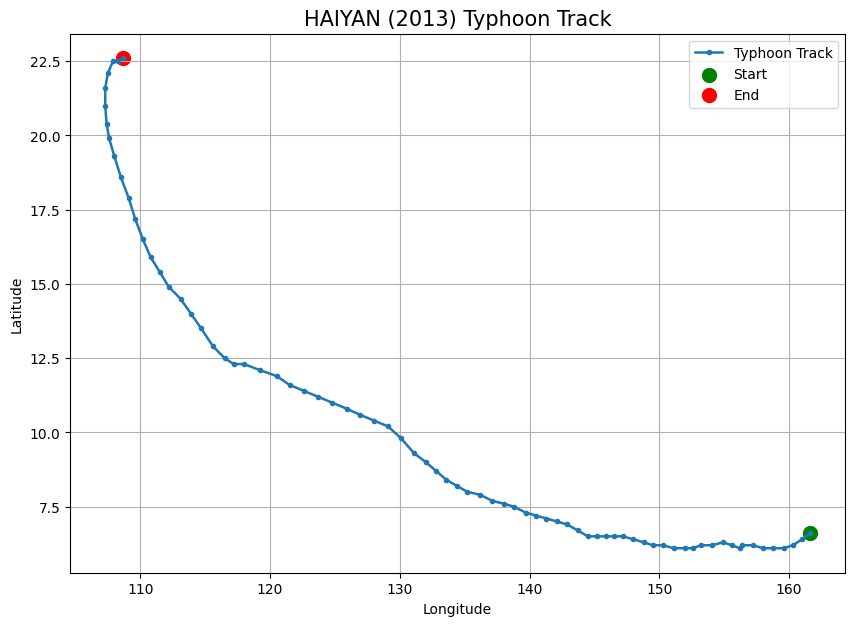

In [6]:

# ==========================================
# 3. 태풍 이동 경로 시각화
# ==========================================

plt.figure(figsize=(10, 7))

plt.plot(
    storm['LON'],
    storm['LAT'],
    marker='o',
    markersize=3,
    linewidth=1.8,
    label='Typhoon Track'
)

# 시작 위치
plt.scatter(
    storm['LON'].iloc[0],
    storm['LAT'].iloc[0],
    color='green',
    s=100,
    label='Start'
)

# 마지막 위치
plt.scatter(
    storm['LON'].iloc[-1],
    storm['LAT'].iloc[-1],
    color='red',
    s=100,
    label='End'
)

plt.title(
    f'{selected_name} ({selected_year}) Typhoon Track',
    fontsize=15
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.grid(True)
plt.legend()
plt.show()


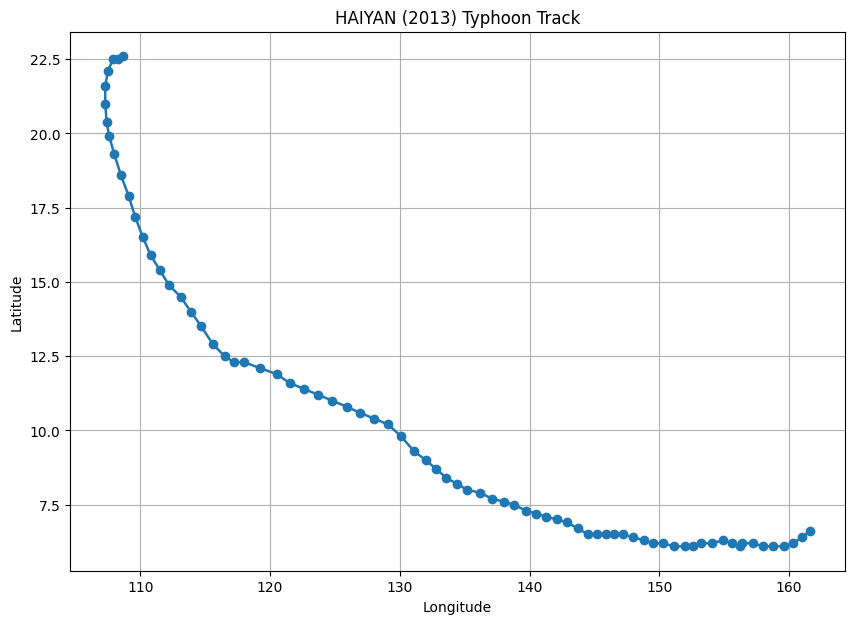

이동 경로 그래프 저장 완료!


In [7]:

plt.figure(figsize=(10, 7))

plt.plot(
    storm['LON'],
    storm['LAT'],
    marker='o',
    linewidth=1.8
)

plt.title(f'{selected_name} ({selected_year}) Typhoon Track')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)

plt.savefig(
    'typhoon_track.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("이동 경로 그래프 저장 완료!")


In [8]:

# ==========================================
# 1. 풍속 및 중심기압 데이터 확인
# ==========================================

display(
    storm[
        ['ISO_TIME', 'NAME', 'LAT', 'LON',
         'WMO_WIND', 'WMO_PRES']
    ].head(15)
)

print("평균 풍속:", storm['WMO_WIND'].mean(), "knot")
print("최대 풍속:", storm['WMO_WIND'].max(), "knot")
print("평균 중심기압:", storm['WMO_PRES'].mean(), "hPa")
print("최저 중심기압:", storm['WMO_PRES'].min(), "hPa")


,ISO_TIME,NAME,LAT,LON,WMO_WIND,WMO_PRES
223105,2013-11-02 06:00:00,HAIYAN,6.6,161.6,NaN,NaN
223106,2013-11-02 09:00:00,HAIYAN,6.4,161.0,NaN,NaN
223107,2013-11-02 12:00:00,HAIYAN,6.2,160.3,NaN,NaN
223108,2013-11-02 15:00:00,HAIYAN,6.1,159.6,NaN,NaN
223109,2013-11-02 18:00:00,HAIYAN,6.1,158.8,NaN,NaN
223110,2013-11-02 21:00:00,HAIYAN,6.1,158.0,NaN,NaN
223111,2013-11-03 00:00:00,HAIYAN,6.2,157.2,NaN,NaN
223112,2013-11-03 03:00:00,HAIYAN,6.2,156.4,NaN,NaN
223113,2013-11-03 06:00:00,HAIYAN,6.1,156.2,NaN,1004.0
223114,2013-11-03 09:00:00,HAIYAN,6.2,155.6,NaN,NaN


평균 풍속: 80.17241379310344 knot
최대 풍속: 125.0 knot
평균 중심기압: 956.7272727272727 hPa
최저 중심기압: 895.0 hPa


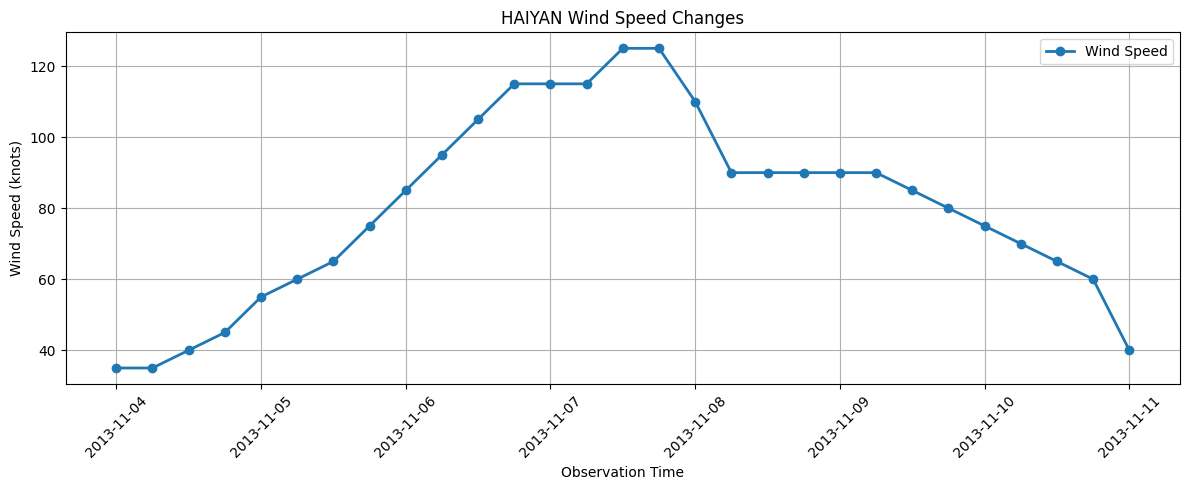

In [9]:

# ==========================================
# 2. 풍속 변화 시각화
# ==========================================

wind_data = storm.dropna(subset=['WMO_WIND']).copy()

plt.figure(figsize=(12, 5))

plt.plot(
    wind_data['ISO_TIME'],
    wind_data['WMO_WIND'],
    marker='o',
    linewidth=2,
    label='Wind Speed'
)

plt.title(f'{selected_name} Wind Speed Changes')
plt.xlabel('Observation Time')
plt.ylabel('Wind Speed (knots)')

plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('typhoon_wind.png', dpi=300)
plt.show()


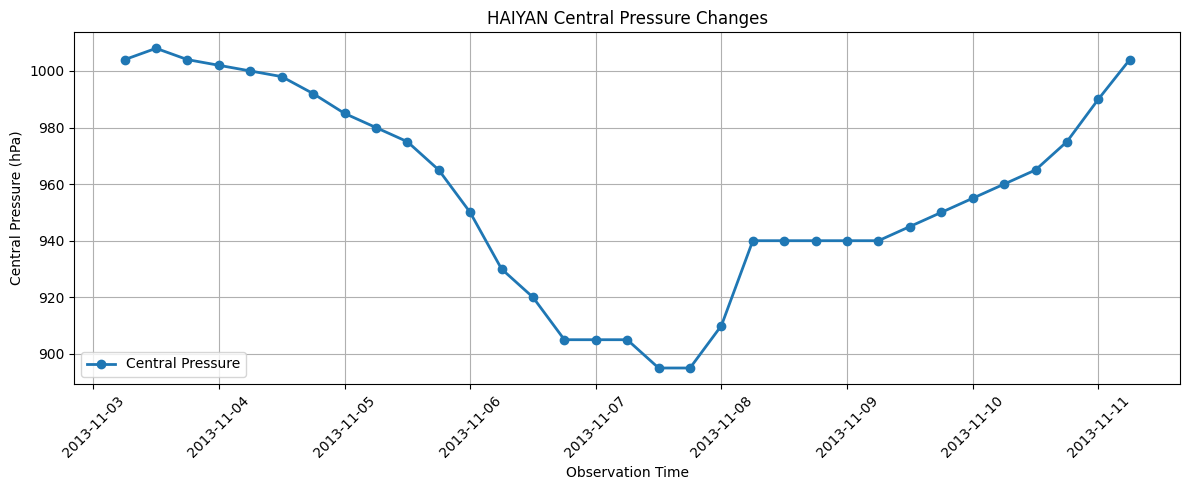

In [10]:

# ==========================================
# 3. 중심기압 변화 시각화
# ==========================================

pressure_data = storm.dropna(subset=['WMO_PRES']).copy()

plt.figure(figsize=(12, 5))

plt.plot(
    pressure_data['ISO_TIME'],
    pressure_data['WMO_PRES'],
    marker='o',
    linewidth=2,
    label='Central Pressure'
)

plt.title(f'{selected_name} Central Pressure Changes')
plt.xlabel('Observation Time')
plt.ylabel('Central Pressure (hPa)')

plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('typhoon_pressure.png', dpi=300)
plt.show()


In [11]:

# ==========================================
# 4. 태풍 강도 분석 결과
# ==========================================

result = pd.DataFrame({
    '분석 항목': [
        '평균 풍속 (knot)',
        '최대 풍속 (knot)',
        '최저 중심기압 (hPa)',
        '평균 중심기압 (hPa)'
    ],
    '분석 결과': [
        wind_data['WMO_WIND'].mean(),
        wind_data['WMO_WIND'].max(),
        pressure_data['WMO_PRES'].min(),
        pressure_data['WMO_PRES'].mean()
    ]
})

display(result.round(2))

print("강도 분석 완료!")


,분석 항목,분석 결과
0,평균 풍속 (knot),80.17
1,최대 풍속 (knot),125.00
2,최저 중심기압 (hPa),895.00
3,평균 중심기압 (hPa),956.73


강도 분석 완료!


In [12]:

# ==========================================
# 5단계 - 1. 기본 태풍 위치 예측 모델
# ==========================================

# 1. 분석 데이터 정리
model_data = storm[
    ['ISO_TIME', 'LAT', 'LON']
].dropna().copy()

model_data = model_data.sort_values('ISO_TIME')
model_data = model_data.drop_duplicates(
    subset=['ISO_TIME']
).reset_index(drop=True)

# 경도를 -180 ~ 180 범위로 변환
model_data['LON'] = (
    (model_data['LON'] + 180) % 360
) - 180

# 날짜와 좌표를 배열로 저장
times = model_data['ISO_TIME'].to_numpy()
latitudes = model_data['LAT'].to_numpy()
longitudes = model_data['LON'].to_numpy()

# 경도 180도 경계에서 이동량이 잘못 계산되지 않도록 처리
unwrapped_lon = np.rad2deg(
    np.unwrap(np.deg2rad(longitudes))
)

# 2. 두 지점의 이동 속도로 다음 위치 예측
predictions = []

for i in range(2, len(model_data)):

    # 이전 두 관측 시점의 시간 차이
    previous_hours = (
        times[i-1] - times[i-2]
    ) / np.timedelta64(1, 'h')

    # 현재 지점에서 다음 지점까지의 시간 차이
    future_hours = (
        times[i] - times[i-1]
    ) / np.timedelta64(1, 'h')

    if previous_hours <= 0 or future_hours <= 0:
        continue

    # 위도와 경도의 시간당 이동량
    lat_speed = (
        latitudes[i-1] - latitudes[i-2]
    ) / previous_hours

    lon_speed = (
        unwrapped_lon[i-1] - unwrapped_lon[i-2]
    ) / previous_hours

    # 다음 위치 예측
    predicted_lat = (
        latitudes[i-1] + lat_speed * future_hours
    )

    predicted_lon_unwrapped = (
        unwrapped_lon[i-1] + lon_speed * future_hours
    )

    # 예측 경도를 -180 ~ 180 범위로 변환
    predicted_lon = (
        (predicted_lon_unwrapped + 180) % 360
    ) - 180

    predictions.append({
        '예측시각': times[i],
        '실제위도': latitudes[i],
        '실제경도': longitudes[i],
        '예측위도': predicted_lat,
        '예측경도': predicted_lon
    })

# 3. 예측 결과 표 생성
prediction_df = pd.DataFrame(predictions)

print("예측 모델 실행 완료!")
print("예측 비교 횟수:", len(prediction_df))

display(prediction_df.head(10))


예측 모델 실행 완료!
예측 비교 횟수: 73


,예측시각,실제위도,실제경도,예측위도,예측경도
0,2013-11-02 12:00:00,6.2,160.3,6.2,160.4
1,2013-11-02 15:00:00,6.1,159.6,6.0,159.6
2,2013-11-02 18:00:00,6.1,158.8,6.0,158.9
3,2013-11-02 21:00:00,6.1,158.0,6.1,158.0
4,2013-11-03 00:00:00,6.2,157.2,6.1,157.2
5,2013-11-03 03:00:00,6.2,156.4,6.3,156.4
6,2013-11-03 06:00:00,6.1,156.2,6.2,155.6
7,2013-11-03 09:00:00,6.2,155.6,6.0,156.0
8,2013-11-03 12:00:00,6.3,154.9,6.3,155.0
9,2013-11-03 15:00:00,6.2,154.1,6.4,154.2


In [13]:

# ==========================================
# 5단계 - 2. 실제 위치와 예측 위치 비교
# ==========================================

def calculate_distance(lat1, lon1, lat2, lon2):
    """두 좌표 사이의 거리를 km로 계산"""

    earth_radius = 6371.0

    lat1 = np.radians(lat1)
    lat2 = np.radians(lat2)
    lon1 = np.radians(lon1)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # 경도 차이를 가장 짧은 방향으로 보정
    dlon = (dlon + np.pi) % (2 * np.pi) - np.pi

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius * c


# 각 예측 위치의 오차 계산
prediction_df['오차_km'] = calculate_distance(
    prediction_df['실제위도'],
    prediction_df['실제경도'],
    prediction_df['예측위도'],
    prediction_df['예측경도']
)

# 평균 및 최대 오차
mean_error = prediction_df['오차_km'].mean()
max_error = prediction_df['오차_km'].max()
min_error = prediction_df['오차_km'].min()

print("평균 위치 오차:", round(mean_error, 2), "km")
print("최대 위치 오차:", round(max_error, 2), "km")
print("최소 위치 오차:", round(min_error, 2), "km")


평균 위치 오차: 15.08 km
최대 위치 오차: 67.26 km
최소 위치 오차: 0.0 km


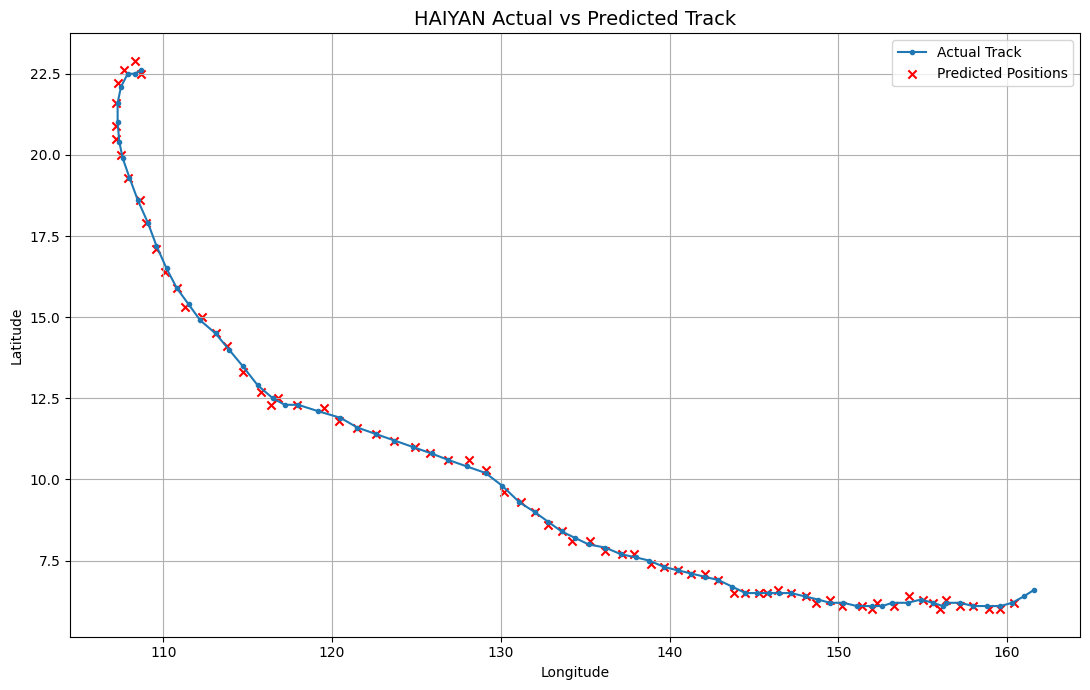

In [14]:

# ==========================================
# 5단계 - 3. 실제 경로와 예측 경로 비교
# ==========================================

plt.figure(figsize=(11, 7))

# 실제 태풍 경로
plt.plot(
    model_data['LON'],
    model_data['LAT'],
    marker='o',
    markersize=3,
    label='Actual Track'
)

# 예측 위치
plt.scatter(
    prediction_df['예측경도'],
    prediction_df['예측위도'],
    color='red',
    marker='x',
    s=35,
    label='Predicted Positions'
)

plt.title(
    f'{selected_name} Actual vs Predicted Track',
    fontsize=14
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    'typhoon_prediction_comparison.png',
    dpi=300
)

plt.show()


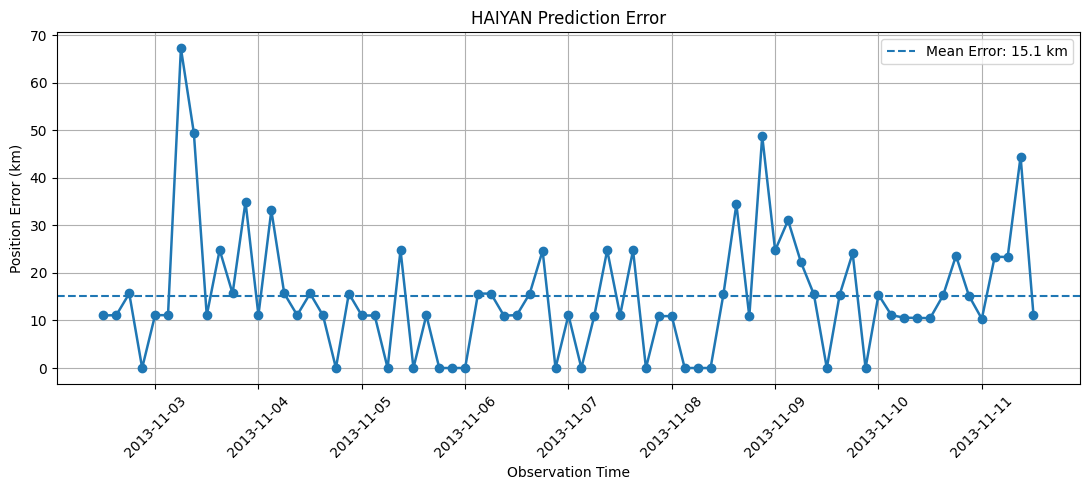

In [15]:

# ==========================================
# 5단계 - 4. 예측 오차 변화
# ==========================================

plt.figure(figsize=(11, 5))

plt.plot(
    prediction_df['예측시각'],
    prediction_df['오차_km'],
    marker='o',
    linewidth=1.8
)

plt.axhline(
    mean_error,
    linestyle='--',
    label=f'Mean Error: {mean_error:.1f} km'
)

plt.title(f'{selected_name} Prediction Error')
plt.xlabel('Observation Time')
plt.ylabel('Position Error (km)')

plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'typhoon_prediction_error.png',
    dpi=300
)

plt.show()


In [16]:

# ==========================================
# 5단계 - 5. 미래 위치 예측
# ==========================================

if len(model_data) < 2:
    print("예측에 필요한 관측 기록이 부족합니다.")

else:
    last_time = times[-1]
    previous_time = times[-2]

    hours = (
        last_time - previous_time
    ) / np.timedelta64(1, 'h')

    if hours <= 0:
        print("관측 시간 간격을 확인해야 합니다.")

    else:
        # 시간당 이동량 계산
        lat_speed = (
            latitudes[-1] - latitudes[-2]
        ) / hours

        lon_speed = (
            unwrapped_lon[-1] - unwrapped_lon[-2]
        ) / hours

        # 6시간 후 위치 예측
        future_lat = latitudes[-1] + lat_speed * 6

        future_lon_raw = unwrapped_lon[-1] + lon_speed * 6

        future_lon = (
            (future_lon_raw + 180) % 360
        ) - 180

        print("태풍:", selected_name)
        print("마지막 관측 시각:", last_time)
        print("예측 시각:", last_time + np.timedelta64(6, 'h'))
        print("6시간 후 예측 위도:", round(future_lat, 3))
        print("6시간 후 예측 경도:", round(future_lon, 3))


태풍: HAIYAN
마지막 관측 시각: 2013-11-11T12:00:00.000000000
예측 시각: 2013-11-11T18:00:00.000000000
6시간 후 예측 위도: 22.8
6시간 후 예측 경도: 109.5


In [17]:

# ==========================================
# 6단계 - 1. 머신러닝 학습 데이터 생성
# ==========================================

ml_df = typhoon_df.copy()

# 결측치 정리
ml_df = ml_df.dropna(
    subset=['SID', 'ISO_TIME', 'LAT', 'LON']
).copy()

# 경도 범위 통일
ml_df['LON'] = (
    (ml_df['LON'] + 180) % 360
) - 180

# 태풍별 시간순 정렬
ml_df = ml_df.sort_values(
    ['SID', 'ISO_TIME']
).reset_index(drop=True)

# 이전 관측 정보 생성
ml_df['PREV_LAT'] = ml_df.groupby('SID')['LAT'].shift(1)
ml_df['PREV_LON'] = ml_df.groupby('SID')['LON'].shift(1)

# 다음 관측 정보 생성
ml_df['NEXT_LAT'] = ml_df.groupby('SID')['LAT'].shift(-1)
ml_df['NEXT_LON'] = ml_df.groupby('SID')['LON'].shift(-1)

# 이전 관측 시점과 현재 관측 시점의 시간 차이
ml_df['TIME_GAP'] = (
    ml_df['ISO_TIME'] -
    ml_df.groupby('SID')['ISO_TIME'].shift(1)
).dt.total_seconds() / 3600

# 현재 관측 시점과 다음 관측 시점의 시간 차이
ml_df['NEXT_GAP'] = (
    ml_df.groupby('SID')['ISO_TIME'].shift(-1) -
    ml_df['ISO_TIME']
).dt.total_seconds() / 3600

# 필요한 정보만 선택
ml_df = ml_df.dropna(
    subset=[
        'PREV_LAT', 'PREV_LON',
        'NEXT_LAT', 'NEXT_LON',
        'TIME_GAP', 'NEXT_GAP'
    ]
).copy()

# 비정상적으로 긴 관측 간격 제외
ml_df = ml_df[
    (ml_df['TIME_GAP'] > 0) &
    (ml_df['NEXT_GAP'] > 0) &
    (ml_df['TIME_GAP'] <= 24) &
    (ml_df['NEXT_GAP'] <= 24)
].copy()

print("머신러닝 학습 데이터 생성 완료!")
print("학습 데이터 크기:", ml_df.shape)

display(ml_df.head())


머신러닝 학습 데이터 생성 완료!
학습 데이터 크기: (240747, 14)


,SID,SEASON,NAME,ISO_TIME,LAT,LON,WMO_WIND,WMO_PRES,PREV_LAT,PREV_LON,NEXT_LAT,NEXT_LON,TIME_GAP,NEXT_GAP
1,1884177N17124,1884,UNNAMED,1884-06-24 18:00:00,16.5,123.8,NaN,NaN,16.5,124.0,16.6,123.5,2.0,3.0
2,1884177N17124,1884,UNNAMED,1884-06-24 21:00:00,16.6,123.5,NaN,NaN,16.5,123.8,16.7,123.2,3.0,3.0
3,1884177N17124,1884,UNNAMED,1884-06-25 00:00:00,16.7,123.2,NaN,NaN,16.6,123.5,16.8,122.9,3.0,3.0
4,1884177N17124,1884,UNNAMED,1884-06-25 03:00:00,16.8,122.9,NaN,NaN,16.7,123.2,16.8,122.8,3.0,1.0
5,1884177N17124,1884,UNNAMED,1884-06-25 04:00:00,16.8,122.8,NaN,NaN,16.8,122.9,16.9,122.6,1.0,2.0


In [18]:

# ==========================================
# 6단계 - 2. 학습 데이터 분리
# ==========================================

features = [
    'PREV_LAT',
    'PREV_LON',
    'LAT',
    'LON',
    'TIME_GAP',
    'NEXT_GAP'
]

targets = [
    'NEXT_LAT',
    'NEXT_LON'
]

X = ml_df[features]
y = ml_df[targets]

# SID 기준으로 학습용과 테스트용 태풍 분리
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=ml_df['SID'])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)
print("학습 태풍 수:", ml_df.iloc[train_idx]['SID'].nunique())
print("테스트 태풍 수:", ml_df.iloc[test_idx]['SID'].nunique())


학습 데이터: (192614, 6)
테스트 데이터: (48133, 6)
학습 태풍 수: 3401
테스트 태풍 수: 851


In [19]:

# ==========================================
# 6단계 - 3. Random Forest 모델 학습
# ==========================================

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("랜덤 포레스트 학습 완료!")


랜덤 포레스트 학습 완료!


In [20]:

# ==========================================
# 6단계 - 4. 머신러닝 예측 결과 평가
# ==========================================

ml_predictions = model.predict(X_test)

ml_result = pd.DataFrame({
    '실제위도': y_test['NEXT_LAT'].to_numpy(),
    '실제경도': y_test['NEXT_LON'].to_numpy(),
    '예측위도': ml_predictions[:, 0],
    '예측경도': ml_predictions[:, 1]
})

ml_result['오차_km'] = calculate_distance(
    ml_result['실제위도'],
    ml_result['실제경도'],
    ml_result['예측위도'],
    ml_result['예측경도']
)

print("머신러닝 평균 위치 오차:",
      round(ml_result['오차_km'].mean(), 2), "km")

print("머신러닝 최대 위치 오차:",
      round(ml_result['오차_km'].max(), 2), "km")

display(ml_result.head(10))


머신러닝 평균 위치 오차: 52.27 km
머신러닝 최대 위치 오차: 13841.39 km


,실제위도,실제경도,예측위도,예측경도,오차_km
0,11.5,127.5,11.066641,127.821851,59.613600
1,11.9,127.0,11.785761,127.008126,12.733593
2,12.3,126.5,12.102203,126.590541,24.094981
3,12.4,126.4,12.443425,126.091705,33.824805
4,12.6,126.2,12.539921,126.028002,19.826289
5,12.8,125.9,12.827699,125.843004,6.904804
6,13.0,125.6,13.020992,125.524759,8.479293
7,13.1,125.4,13.111675,125.122203,30.113081
8,13.2,125.3,13.285572,124.967409,37.235261
9,13.4,125.1,13.355695,124.866564,25.728662


,모델,평균 위치 오차(km)
0,기본 이동 모델,13.90
1,Random Forest,52.27


/tmp/ipykernel_1898/1549473580.py:58: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1898/1549473580.py:58: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1898/1549473580.py:58: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1898/1549473580.py:58: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1898/1549473580.py:58: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1898/1549473580.py:58: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1898/1549473580.py:59: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.savefig('mo

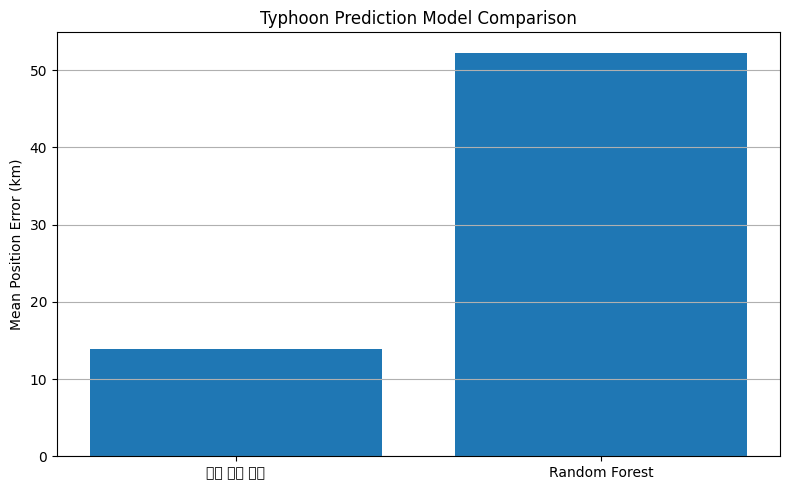

In [21]:

# ==========================================
# 6단계 - 5. 모델 성능 비교
# ==========================================

# 기본 모델의 예측 결과를 동일한 테스트 행에 대해 계산
test_rows = ml_df.iloc[test_idx].copy()

baseline_lat = (
    test_rows['LAT']
    + (test_rows['LAT'] - test_rows['PREV_LAT'])
    / test_rows['TIME_GAP']
    * test_rows['NEXT_GAP']
)

baseline_lon_unwrapped = (
    test_rows['LON']
    + (
        (
            (test_rows['LON'] - test_rows['PREV_LON'] + 180)
            % 360
        ) - 180
    ) / test_rows['TIME_GAP']
    * test_rows['NEXT_GAP']
)

baseline_lon = (
    (baseline_lon_unwrapped + 180) % 360
) - 180

baseline_error = calculate_distance(
    test_rows['NEXT_LAT'].to_numpy(),
    test_rows['NEXT_LON'].to_numpy(),
    baseline_lat.to_numpy(),
    baseline_lon.to_numpy()
)

ml_error = ml_result['오차_km'].to_numpy()

comparison = pd.DataFrame({
    '모델': ['기본 이동 모델', 'Random Forest'],
    '평균 위치 오차(km)': [
        baseline_error.mean(),
        ml_error.mean()
    ]
})

display(comparison.round(2))

plt.figure(figsize=(8, 5))
plt.bar(
    comparison['모델'],
    comparison['평균 위치 오차(km)']
)

plt.title('Typhoon Prediction Model Comparison')
plt.ylabel('Mean Position Error (km)')
plt.grid(axis='y')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300)
plt.show()
